# Figure 8 — Parameter trajectories on the fig1 Toffoli problem

Figure 1 compares the five optimisers by infidelity. This notebook asks how
they move through parameter space $\mathbb R^{L K_\mathrm{ctrl}}$ ($K_\mathrm{ctrl}=6$ for three
atoms with $\sigma^x_i,\sigma^z_i$ controls), on the same problem and from the same seeded
initial pulses. Do the GRAPE rules follow longer or more erratic paths than GEOPE does?

The fig1 cache keeps only fidelities, so `traj_common.py` re-runs seeds 0–19 of every
block with the free parameters recorded at each step. GEOPE and LBFGS reproduce the
fig1 fidelity curves bit for bit. The three Newton rules differ slightly, by a few
iterations, because commit `1caf60c` (*fix defaults*) came after their fig1 blocks were
cached.

All distances are Euclidean in $\phi$. The chart is not $2\pi$-periodic per
coordinate once the generators fail to commute, so there is no smaller equivalent
metric to reduce to. A large $\|\phi\|$ therefore means a larger pulse area, which is not
automatically a worse solution.

In [ ]:
from traj_common import *
from traj_common import METHODS

N_RUNS = 20
CASES = [120,]
SPREADS = [1.0,]

In [2]:
traj = {
    (spread, steps, method): trajectory_block(steps, method, spread, N_RUNS, verbose=False)
    for spread in SPREADS
    for steps in CASES
    for method in METHODS
}
table = pd.DataFrame(
    [
        {"spread": s, "L": L, "method": m, **metrics(r)}
        for (s, L, m), runs in traj.items()
        for r in runs
    ]
)
assert (table.disp <= table.excursion + 1e-12).all()
assert (table.excursion <= table.path + 1e-12).all()

### Trajectories in their own principal plane

A random coordinate plane catches only a small part of a step that moves hundreds of
coordinates together. Here each trajectory $\phi_0,\dots,\phi_n$ is instead projected
onto its **own** top two principal components, for the first `N_TRAJ` seeds of the
block `PCA_CASE`. This is an orthogonal projection, so
distances are true, but it is the plane that captures the most motion. Every path starts at the
origin (the start is subtracted), with the PC signs chosen so it ends in the positive
quadrant. All panels share the same axes, so lengths compare directly across methods. With `AXIS_SCALE = "symlog"` (the default)
the axes are linear within $\pm1$ and logarithmic beyond, so GEOPE's paths, of length
about 1, and the Newton jumps, of length up to about 500, fit on one set of axes;
`"linear"` keeps true geometry instead.

The table then quantifies how spread a step is. The participation ratio
$\mathrm{PR}=\|\Delta\phi\|_2^4/\|\Delta\phi\|_4^4$ is the effective number of
coordinates a step moves: $P$ if the step is spread evenly, and 1 if only one
coordinate moves. `PR_frac` is $\mathrm{PR}/P$, the median over every step of all
20 seeds. `pc2_share` is the median share of variance in the principal plane.


figures/fig8_parameter_pca_L120_spread1pi.pdf


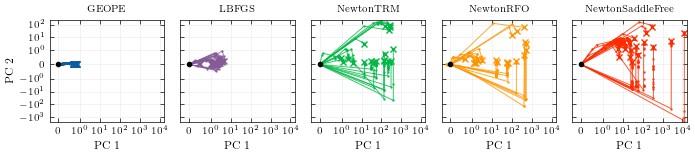

In [4]:
def principal_plane(phi):
    """Project a trajectory on its top-2 PCs. Returns ``(coords (n+1, 2), variance share)``.

    Centred at the start so the initial pulse sits at the origin; the PCs are those of
    the mean-centred path. Signs are flipped so the end lies in the positive quadrant,
    which makes panels comparable -- a PC's sign is arbitrary.
    """
    X = phi - phi[0]
    _, sv, Vt = np.linalg.svd(X - X.mean(0), full_matrices=False)
    Y = X @ Vt[:2].T
    Y *= np.where(Y[-1] < 0, -1, 1)
    return Y, float((sv[:2] ** 2).sum() / (sv**2).sum())


def participation_ratio(steps):
    """Effective number of coordinates each row of ``steps`` moves."""
    return (steps**2).sum(-1) ** 2 / np.maximum((steps**4).sum(-1), 1e-300)


PCA_CASE = (1.0, 120)  # (spread, L): which block the row shows
N_TRAJ = 20  # seeds overlaid per panel, 0 .. N_TRAJ - 1
SYMLOG_LINEAR = 1.0

spread, steps = PCA_CASE
planes = {
    method: [principal_plane(r["phi"])[0] for r in traj[(spread, steps, method)][:N_TRAJ]]
    for method in METHODS
}
# One set of limits for every panel, so a length reads the same in each column.
everything = np.concatenate([Y for Ys in planes.values() for Y in Ys])
lo, hi = everything.min(0), everything.max(0)
lo, hi = 1.3 * np.minimum(lo, -0.3 * SYMLOG_LINEAR), 1.3 * np.maximum(hi, 0)

xlim, ylim = (lo[0], hi[0]), (lo[1], hi[1])


def symlog_ticks(lim):
    """0 and the signed powers of ten inside ``lim``, from ``SYMLOG_LINEAR`` up."""
    powers = SYMLOG_LINEAR * 10.0 ** np.arange(0, 6)
    return [-p for p in powers[::-1] if -p >= lim[0]] + [0] + [p for p in powers if p <= lim[1]]


fig, axes = plt.subplots(1, len(METHODS), figsize=(TWO_COLUMN, 1.7),
                         sharex=True, sharey=True)
for ax, method in zip(axes, METHODS):
    for Y in planes[method]:
        ax.plot(Y[:, 0], Y[:, 1], color=COLOURS[method], lw=0.7, alpha=0.8,
                marker=".", ms=1.5)
        ax.plot(*Y[-1], "x", color=COLOURS[method], ms=4, mew=1)
    ax.plot(0, 0, "ko", ms=3, zorder=5)  # every path starts at the origin
    ax.set_xscale("symlog", linthresh=SYMLOG_LINEAR)
    ax.set_yscale("symlog", linthresh=SYMLOG_LINEAR)
    ax.set_xticks(symlog_ticks(xlim))
    ax.set_yticks(symlog_ticks(ylim))
    ax.minorticks_off()

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(alpha=0.25, lw=0.4)
    ax.set_title(method, fontsize=LABEL_FONT_SIZE)
    ax.set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")
# fig.suptitle(rf"$L={steps}$, spread ${spread:g}\pi$, seeds 0–{N_TRAJ - 1}",
#              fontsize=LABEL_FONT_SIZE, y=1.02)
fig.tight_layout()
print(save_figure(fig, f"fig8_parameter_pca_L{steps}_{spread_slug(spread)}"))
plt.show()


